In [1]:
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(0) # RNG

In [2]:
X = np.loadtxt('../_data_/qm9_c_abobrbf0_di.dat')
y = np.loadtxt('../_data_/qm9_c_abobrbf0_pi.dat')
print(X.shape, y.shape)

X = torch.as_tensor(X, dtype=torch.float32)
y = torch.as_tensor(y, dtype=torch.float32).view(-1, 1)
print(X.shape, y.shape)

(1000, 1665) (1000,)
torch.Size([1000, 1665]) torch.Size([1000, 1])


In [3]:
N = X.shape[0]
test_N = int(N * 0.2)

X_test, y_test = X[:test_N], y[:test_N]
X_train, y_train = X[test_N:], y[test_N:]

In [5]:
train_ds = TensorDataset(X_train, y_train)
test_ds = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False)

In [6]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [7]:
model = nn.Sequential(
    nn.Linear(X.shape[1], 1024),
    nn.ReLU(),
    nn.Linear(1024, 512),
    nn.Tanh(),
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.Tanh(),
    nn.Linear(64, 1),
).to(device)

In [8]:
loss_fxn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [ ]:
# Training loop

EPOCHS = 1000

for epoch in range(EPOCHS):

    model.train()
    running_loss = 0.0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        preds = model(xb)
        loss = loss_fxn(preds, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * xb.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1:02d} | Train MSE: {epoch_loss:.4f}")

Epoch 50 | Train MSE: 11671.2238
Epoch 100 | Train MSE: 8939.7039
Epoch 150 | Train MSE: 6633.2383
Epoch 200 | Train MSE: 4732.6200
Epoch 250 | Train MSE: 3210.1680
Epoch 300 | Train MSE: 2045.3797
Epoch 350 | Train MSE: 1216.6917
Epoch 400 | Train MSE: 657.4850
Epoch 450 | Train MSE: 309.0932
Epoch 500 | Train MSE: 125.3109
Epoch 550 | Train MSE: 42.2412
Epoch 600 | Train MSE: 11.9448
Epoch 650 | Train MSE: 3.0042
Epoch 700 | Train MSE: 0.7670
Epoch 750 | Train MSE: 0.4632
Epoch 800 | Train MSE: 0.4635
Epoch 850 | Train MSE: 0.2027
Epoch 900 | Train MSE: 0.0779
Epoch 950 | Train MSE: 0.4009
Epoch 1000 | Train MSE: 0.1313


In [ ]:
model.eval()
with torch.no_grad(): 
    yhat = []
    for xb, _ in test_loader:
        preds = model(xb).cpu()
        yhat.append(preds)
    yhat = torch.cat(yhat).squeeze().numpy()

test_y = y_test.squeeze().numpy()

In [ ]:
print(f"MAE  = {np.mean(np.abs(test_y - yhat)):.3f}")
print(f"RMSE = {np.sqrt(np.mean((test_y - yhat)**2)):.3f}")

MAE  = 5.183
RMSE = 7.640


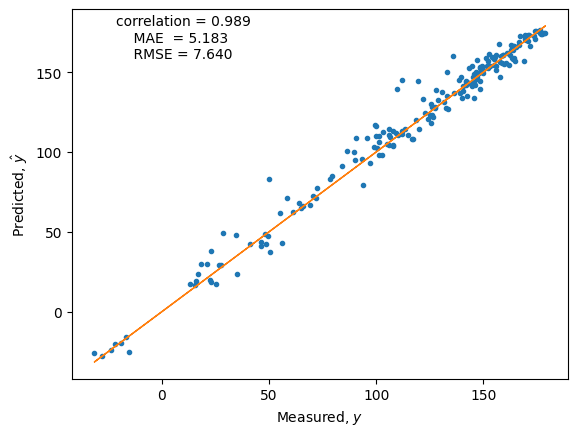

In [21]:
plt.figure()
plt.plot(test_y, yhat, ".")
plt.plot(test_y, test_y, "-", linewidth=1)
plt.xlabel(r"Measured, $y$")
plt.ylabel(r"Predicted, $\hat{y}$")
plt.text(
    min(test_y) + 10,
    max(test_y) - 20,
    f"correlation = {np.corrcoef(test_y, yhat)[0,1]:.3f} \n\
    MAE  = {np.mean(np.abs(test_y - yhat)):.3f} \n\
    RMSE = {np.sqrt(np.mean((test_y - yhat)**2)):.3f}"
)
plt.show()